In [12]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import truncnorm

amd = yf.Ticker("AMD")



# Financial Statemets:

In [13]:
income_statement = pd.DataFrame(amd.income_stmt)
IS = income_statement.loc[::-1]
IS = IS[IS.columns[::-1]]
IS.drop(IS.columns[0],axis = 1,inplace=True)

balance_sheet = pd.DataFrame(amd.balance_sheet)
BS = balance_sheet.loc[::-1]
BS = BS[BS.columns[::-1]]
BS.drop(BS.columns[0], axis = 1, inplace=True)
pd.set_option('display.max.rows', 80)
pd.set_option('display.max.columns', 5)


cash_flow_statement = pd.DataFrame(amd.cashflow)
CFS = cash_flow_statement.loc[::-1]
CFS = CFS[CFS.columns[::-1]]
CFS.drop(CFS.columns[0], axis = 1, inplace=True)
pd.set_option('display.max.rows', 61)
pd.set_option('display.max.columns', 5)


In [14]:
#To show sheet
pd.set_option('display.max.rows', 80)
pd.set_option('display.max.columns', 5)

# Assumptions:

In [15]:
#yield calculator
def yield_calculator():
    ten_yr_yield = yf.Ticker('^TNX')
    latest_data = ten_yr_yield.history(period="1d")
    recent_yield = (latest_data['Close'].iloc[0])/100
    print(f'Current U.S. 10 Year Yield: {round(recent_yield * 100, 2)}%')
    return(recent_yield)
recent_yield = yield_calculator()

Current U.S. 10 Year Yield: 4.89%


In [16]:
#years
total_years = 9
projected_years = 5
historical_years = 4
current_year = 2025

#NOPAT Assumptions
yoy_revenue_growth_assumption = 0.40
decay_rate_assumption = 0.05 #mckinsey fade
corporate_tax_rate = 0.21
starting_base_revenue = IS.iloc[0, -1]

#PPs Assumptions
shares_outstanding = amd.info.get('sharesOutstanding')
share_dilution_rate = 0.01
#TV
ebitda_multiple = 35

#wacc assumptions
price = amd.info.get('currentPrice')
market_cap = amd.info.get('marketCap')
if not isinstance(market_cap, float):
    market_cap =  amd.info.get('currentPrice') *  amd.info.get('sharesOutstanding')

raw_beta = amd.info.get('beta')
adjusted_beta = (2/3 * raw_beta) + (1/3 * 1)
expected_market_return = .10
risk_free_rate = recent_yield

#peers
peers = ['AVGO', 'INTC', 'MRVL', 'NVDA']


In [17]:
D =  int(BS.loc['Current Debt', '2025-12-31'] + BS.loc['Long Term Debt', '2025-12-31']) #BS.loc['row data, 'column data']

#Hamada method to find beta
peers = ['AVGO', 'INTC', 'MRVL', 'NVDA']
corporate_tax_rate = 0.21

try:
    def hamada_beta(peers,corporate_tax_rate):
        peers_unlevered_adjusted_beta = {}
        peers_levered_adjusted_beta = {}
        for p in peers:
            peer = yf.Ticker(p)
            BS_P = pd.DataFrame(peer.balance_sheet)
            BS_P = BS_P.loc[::-1]
            BS_P = BS_P[BS_P.columns[::-1]]
            raw_p_beta = peer.info.get('beta')
            p_total_debt = int(BS_P.loc['Long Term Debt And Capital Lease Obligation'].iloc[3] + BS_P.loc['Current Debt And Capital Lease Obligation'].iloc[3])
            p_equity = peer.info.get('marketCap')


            peers_levered_adjusted_beta[p] = round(((2/3 * raw_p_beta) + (1/3 * 1)),2)

            beta_unlevered = peers_levered_adjusted_beta[p] / (1 + ((1 - corporate_tax_rate) * (p_total_debt/p_equity))) #ADJUSTED THEN UNLEVERED
            peers_unlevered_adjusted_beta[p] = round(beta_unlevered,2)
            print(f'{p}: {p_total_debt}')

        #adjusted levered and unlevered betas
        array_levered_adjusted_betas = np.array([beta for beta in peers_levered_adjusted_beta.values()])
        array_unlevered_adjusted_betas = np.array([beta for beta in peers_unlevered_adjusted_beta.values()])

        #median
        median_adjusted_unlevered_beta = np.median(array_unlevered_adjusted_betas)


        #amd beta
        amd_total_debt = int(BS.loc['Long Term Debt And Capital Lease Obligation'].iloc[-1] + BS.loc['Current Debt And Capital Lease Obligation'].iloc[-1])
        amd_equity = market_cap
        amd_hamada_beta = median_adjusted_unlevered_beta *  (1 + ((1 - corporate_tax_rate) * (amd_total_debt/amd_equity))) #AMD GETS RELEVERED



            #peer betas relevered with AMD's
        peer_with_relevered_beta = {}

        peer_adjusted_relevered_beta = array_unlevered_adjusted_betas *  (1 + ((1 - corporate_tax_rate) * (amd_total_debt/amd_equity)))

        for p in peers:
            peer_with_relevered_beta[p] = round(float(peer_adjusted_relevered_beta[peers.index(p)]),2)

        print(f'Peer Levered(raw) Adjusted Betas: {peers_levered_adjusted_beta}')
        print(f'Peer Unlevered Betas: {peers_unlevered_adjusted_beta}')
        print(f'Adjusted Median Unlevered Beta: {round(median_adjusted_unlevered_beta,2)}')
        print(f'Peer Betas Re-levered with AMD capital structure: {peer_with_relevered_beta}')
        print(f'AMD Unlevered Beta: {round(amd_hamada_beta,2)}')
        return(peers_unlevered_adjusted_beta,amd_hamada_beta,array_levered_adjusted_betas, array_unlevered_adjusted_betas, peer_adjusted_relevered_beta)

    peers_unlevered_adjusted_beta, amd_hamada_beta, array_levered_adjusted_betas, array_unlevered_adjusted_betas, peer_adjusted_relevered_beta= hamada_beta(peers,corporate_tax_rate)

except TypeError:
    print("Model unable to work. Betas cannot be pulled up from Yahoo finance at the moment")

AVGO: 65136000000
INTC: 50011000000
MRVL: 4343100000
NVDA: 10270000000
Peer Levered(raw) Adjusted Betas: {'AVGO': 1.34, 'INTC': 1.95, 'MRVL': 1.88, 'NVDA': 1.83}
Peer Unlevered Betas: {'AVGO': 1.3, 'INTC': 1.73, 'MRVL': 1.84, 'NVDA': 1.83}
Adjusted Median Unlevered Beta: 1.78
Peer Betas Re-levered with AMD capital structure: {'AVGO': 1.3, 'INTC': 1.74, 'MRVL': 1.85, 'NVDA': 1.84}
AMD Unlevered Beta: 1.79


##  Revenue and EV/EBITDA (Exit) Multiple: Deviation Calculations

In [18]:
#FINDING MEAN AND STD OF REVENUE
def revenue_deviation_calculation(IS, historical_years):
    # Source: Macrotrends, AMD annual revenue (millions USD), as of 2026-07-13
    amd_revenue_historical = {
    2015: 3991, 2016: 4319, 2017: 5253, 2018: 6475, 2019: 6731,
    2020: 9763, 2021: 16434, 2022: 23601, 2023: 22680, 2024: 25785, 2025: 34639
    }
    print(f'AMD Historical Revenue: {amd_revenue_historical}')
    revenue_mc = amd_revenue_historical.values()
    revenue_mc_extracted = np.array([revenue for revenue in revenue_mc])
    yoy_growth_revenue = (revenue_mc_extracted[1:] - revenue_mc_extracted[:-1]) / revenue_mc_extracted[:-1]
    yoy_growth_revenue_clean = [str(round(yoy_revenue, 2)) + '%' for yoy_revenue in yoy_growth_revenue]
    print(f'yoy_growth: {yoy_growth_revenue_clean}')

    mean_yoy_growth_revenue = round(yoy_growth_revenue.mean(),2)
    std_yoy_growth_revenue = round(yoy_growth_revenue.std(),2)
    print(f'Mean yoy_growth(%): {mean_yoy_growth_revenue * 100}%')
    print(f'Standard Deviation of yoy_growth(%) Change: {std_yoy_growth_revenue * 100}%')

    return(mean_yoy_growth_revenue , std_yoy_growth_revenue, yoy_growth_revenue_clean, yoy_growth_revenue)

#EV/EBITDA Multiples calculation
def enterpise_value_to_ebitda_deviation_calculation():
    peers = ['AVGO', 'INTC', 'MRVL', 'NVDA']

    multiples = {}

    for p in peers:
        comparable_stock = yf.Ticker(p)
        multiple = comparable_stock.info.get('enterpriseToEbitda')
        multiples[p] = multiple

    print(multiples)

    multiples_extracted = multiples.values()

    multiples_for_calculation = [int(m) for m in multiples_extracted]

    array_ev_to_ebitda = np.array(multiples_for_calculation)
    median_ev_to_ebitda = np.median(array_ev_to_ebitda)
    std_ev_to_ebitda = array_ev_to_ebitda.std()

    print(f'Median EV/EBITDA: {median_ev_to_ebitda}')
    print(f'STD EV/EBITDA: {round(std_ev_to_ebitda,2)}')

    return(median_ev_to_ebitda, std_ev_to_ebitda, array_ev_to_ebitda)
#output
print('   Revenue MonteCarlo Calculations:')
mean_yoy_growth_revenue , std_yoy_growth_revenue, yoy_growth_revenue_clean, yoy_growth_revenue = revenue_deviation_calculation(IS, historical_years)
print('-' * 80)

print('   EV/EBITDA MonteCarlo Calculations:')
median_ev_to_ebitda, std_ev_to_ebitda,array_ev_to_ebitda = enterpise_value_to_ebitda_deviation_calculation()


   Revenue MonteCarlo Calculations:
AMD Historical Revenue: {2015: 3991, 2016: 4319, 2017: 5253, 2018: 6475, 2019: 6731, 2020: 9763, 2021: 16434, 2022: 23601, 2023: 22680, 2024: 25785, 2025: 34639}
yoy_growth: ['0.08%', '0.22%', '0.23%', '0.04%', '0.45%', '0.68%', '0.44%', '-0.04%', '0.14%', '0.34%']
Mean yoy_growth(%): 26.0%
Standard Deviation of yoy_growth(%) Change: 21.0%
--------------------------------------------------------------------------------
   EV/EBITDA MonteCarlo Calculations:
{'AVGO': 30.409, 'INTC': 16.853, 'MRVL': 49.638, 'NVDA': 23.86}
Median EV/EBITDA: 26.5
STD EV/EBITDA: 12.3


# Monte Carlo Simulation (MCS) Section

## MCS DCF Calculations

In [19]:
#Revenue Growth Simulated
lower_bound = 0.05 #Revenue cannot go below 5%
upper_bound = 0.5 #Revenue cannot go above 50%
a = (lower_bound - yoy_revenue_growth_assumption)/std_yoy_growth_revenue

b = (upper_bound - yoy_revenue_growth_assumption)/std_yoy_growth_revenue


simulations = input('Simulations: ').upper()

def monte_carlo_simulation(simulations):
    try:

        starting_base_revenue = IS.iloc[0, -1]

        #Lists to use for calculations

        revenue_growth_list_monte = []

        revenue_growth_list = []

        ebitda_multiple_list = []

        equity_values = []

        wacc_values = []



        np.random.seed(42)

        for i in range(int(simulations)):

            revenue = IS.loc['Operating Revenue'].dropna().tolist()

            cogs = IS.loc['Cost Of Revenue'].dropna().tolist()

            capex = CFS.loc['Capital Expenditure'].dropna().tolist()

            ppe_gross = BS.loc['Gross PPE'].dropna().tolist()

            depreciation_expense = CFS.loc['Depreciation'].dropna().tolist()

            amortization_expense = IS.loc['Amortization'].dropna().tolist()

            sga = IS.loc['Selling General And Administration'].dropna().tolist()

            rnd = IS.loc['Research And Development'].dropna().tolist()


            #[REVENUE]

            revenue_growth_simulated = truncnorm.rvs(a,b,loc = yoy_revenue_growth_assumption, scale = std_yoy_growth_revenue) #reshaped distribution


            revenue_monte = starting_base_revenue



            for year in range(1, projected_years + 1):

                if year <= 2: #elevated growth for two years Damodaran's "high growth then linear fade" model
                    decay_rate = 0

                else:
                    decay_rate -= decay_rate_assumption

                revenue_growth_simulated_clipped = np.clip(revenue_growth_simulated, 0, 0.5)

                revenue_growth_list.append(revenue_growth_simulated_clipped)#to show mean

                revenue_growth_decayed = (revenue_growth_simulated_clipped - abs(decay_rate))

                revenue_growth_decayed_clipped = np.clip(revenue_growth_decayed, 0, 0.5)#decayed

                revenue_monte *= (1 + revenue_growth_decayed_clipped) #actual revenue

                revenue_growth_simulated_clipped = revenue_growth_decayed

                revenue.append(revenue_monte)

            #[COGS]

            cogs_percent_of_revenue_list = []



            for historical_yrs in range(len(cogs)):

                cogs_percent_of_revenue = cogs[historical_yrs] / revenue[historical_yrs]

                cogs_percent_of_revenue_list.append(round(cogs_percent_of_revenue, 2))



            average_cogs_percent = sum(cogs_percent_of_revenue_list) / len(cogs)

            for forecast_yr in range(projected_years):

                if forecast_yr < 3:

                    cogs_future = average_cogs_percent * revenue[4 + forecast_yr]

                    cogs.append(cogs_future)

                    average_cogs_percent -= 0.01

                elif forecast_yr >= 3:

                    cogs_future = average_cogs_percent * revenue[4 + forecast_yr]

                    cogs.append(cogs_future)



                                                ### GROSS PROFIT ###

            gp = [] #VALUE

            for y in range(total_years):

                profit = revenue[y] - cogs[y]

                gp.append(profit)


                                                ### DEPRECIATION SCHEDULE ###

            #[CAPEX]

            capex_percent_of_revenue_list = []



            for historical_yr in range(len(capex)):

                capex_percent_of_revenue = capex[historical_yr] / revenue[historical_yr]

                capex_percent_of_revenue_list.append(capex_percent_of_revenue)

                average_capex_percent = sum(capex_percent_of_revenue_list) / len(capex)



            for forecast_yrs in range(projected_years):

                capex_future = average_capex_percent * revenue[4 + forecast_yrs]

                capex.append(capex_future)


            #[GROSS PPE]#

            for years in range(projected_years):

                # Using 3 + years matching your original logic tracking index offset

                ppe_gross.append(ppe_gross[3 + years] + abs(capex[4 + years]))



            #[DEPRECIATION]

            historical_depreciation_rate = []



            for historical_yr in range(len(depreciation_expense)):

                rate = depreciation_expense[historical_yr] / ppe_gross[historical_yr]

                historical_depreciation_rate.append(rate)

                avg_rate = sum(historical_depreciation_rate) / len(historical_depreciation_rate)

            for forecast_yr in range(projected_years):

                beginning_ppe = ppe_gross[4 - 1 + forecast_yr]

                depreciation_t = beginning_ppe * avg_rate

                depreciation_expense.append(depreciation_t)



                                                ### AMORTIZATION CALCULATIONS ###

           #Amortization = [Amortizationt current year − 1] ×(1+g)

                # CAGR

            n = len(amortization_expense) - 1

            g_cagr = (amortization_expense[-1] / amortization_expense[0]) ** (1/n) - 1



                # Amortization average YoY growth

            yoy_amortization_growth = []



            for y in range(1, len(amortization_expense)):

                yoy_amortization_growth.append(amortization_expense[y] / amortization_expense[y-1] - 1)



            g_avg = sum(yoy_amortization_growth) / len(yoy_amortization_growth)



            # blended rate

            g = 0.5 * g_cagr + 0.5 * g_avg

            ### [amortization calculations] ###

            for years in range(projected_years):

                projected_amortization = amortization_expense[-1] * (1 + g)

                amortization_expense.append(round(projected_amortization,1))



                                                    ### OPERATING EXPENSES ###

            #[SGA]

            sga_percent_of_revenue_list = []



            for historical_yrs in range(len(sga)):

               sga_percent_of_revenue = sga[historical_yrs]/revenue[historical_yrs]

               sga_percent_of_revenue_list.append(sga_percent_of_revenue)

            sga_margin = sum(sga_percent_of_revenue_list)/len(sga)



            for forecast_yrs in range(projected_years):

                if forecast_yrs < 1:

                    sga_future = sga_margin * revenue[4 + forecast_yrs]

                    sga.append(sga_future)

                elif 1 <= forecast_yrs < 4:

                    sga_margin -= 0.007

                    sga_future =  sga_margin * revenue[4 + forecast_yrs]

                    sga.append(sga_future)

                elif forecast_yrs == 4:

                   sga_future =  sga_margin * revenue[4 + forecast_yrs]

                   sga.append(sga_future)



            #[RND]

            rnd_percent_of_revenue_list = []

            y = 0

            for historical_yrs in range(len(rnd)):

               rnd_percent_of_revenue = rnd[historical_yrs]/revenue[historical_yrs]

               rnd_percent_of_revenue_list.append(rnd_percent_of_revenue)

               rnd_margin = sum(rnd_percent_of_revenue_list)/len(rnd)



            for forecast_yrs in range(projected_years):

                if forecast_yrs < 1:

                    rnd_future = rnd_margin * revenue[4 + forecast_yrs]

                    rnd.append(rnd_future)

                elif 1 <= forecast_yrs < 4:

                    rnd_margin -= 0.02

                    rnd_future =  rnd_margin * revenue[4 + forecast_yrs]

                    rnd.append(rnd_future)

                elif forecast_yrs == 4:

                   rnd_future =  rnd_margin * revenue[4 + forecast_yrs]

                   rnd.append(rnd_future)



            #[D&A]

            depreciation_and_amortization = IS.loc['Depreciation And Amortization In Income Statement'].dropna().tolist() #VALUE

            for y in range(projected_years):

                combined = depreciation_expense[4 + y] + abs(amortization_expense[4 + y])

                depreciation_and_amortization.append(combined)




            #[OTHER OPERATING EXPENSES]

            ooe = IS.loc['Other Operating Expenses'].tolist()

            ooe_percent_of_revenue_list = [] #VALUE



            for historical_yrs in range(len(ooe)):

                ooe_percent_of_revenue = ooe[historical_yrs]/revenue[historical_yrs]

                ooe_percent_of_revenue_list.append(ooe_percent_of_revenue)

            average_ooe_percent = sum(ooe_percent_of_revenue_list)/len(ooe)



            for forecast_yrs in range(projected_years):

                ooe_future = average_ooe_percent * revenue[4 + forecast_yrs]

                ooe.append(ooe_future)



            #[TOTAL OPERATING EXPENSE]

            opex = []

            for y in range(total_years):

                annual_operating_expense = (

                    sga[0 + y]

                    + rnd[0 + y]

                    + depreciation_and_amortization[0 + y]

                )

                opex.append(annual_operating_expense)



                                                ### OPERATING PROFIT ###

            historical_and_projected_ebit = IS.loc['Operating Income'].tolist()

            for y in range(projected_years):

                ebit = (

                    gp[4 + y]

                    - sga[4 + y]

                    - rnd[4 + y]

                    - depreciation_and_amortization[4 + y]

                )

                historical_and_projected_ebit.append(ebit)



                                                ### NOPAT CALCULATIONS ###

            nopat = [ebit * (1-corporate_tax_rate) for ebit in historical_and_projected_ebit]




                                        ### CHANGE IN NET WORKING CAPITAL CALCULATIONS  ###

            #[ACCOUNTS RECEIVABLE]

            accounts_receivable = BS.loc['Accounts Receivable'].tolist()

            dso = [(accounts_receivable[years] * 365) / revenue[years] for years in range(historical_years)]

            avg_dso = sum(dso) / len(dso)



            for years in range(projected_years):

                projected_accounts_receivable = avg_dso * revenue[4 + years] / 365

                accounts_receivable.append(projected_accounts_receivable)



            #[INVENTORY]

            inventory = BS.loc['Inventory'].tolist()

            dio = [(inventory[years] * 365) / cogs[years] for years in range(historical_years)]

            avg_dio = sum(dio) / len(dio)



            for years in range(projected_years):

                projected_inventory = avg_dio * cogs[4 + years] / 365

                inventory.append(projected_inventory)



            #[ACCOUNTS PAYABLE]

            accounts_payable = BS.loc['Accounts Payable'].tolist()

            dpo = [(accounts_payable[years] * 365) / cogs[years] for years in range(historical_years)]

            avg_dpo = sum(dpo) / len(dpo)



            for years in range(projected_years):

                projected_accounts_payable = avg_dpo * cogs[4 + years] / 365

                accounts_payable.append(projected_accounts_payable)



            #[ACCURED EXPENSES]


            accured_expenses = BS.loc['Current Accrued Expenses'].tolist()

            ae_percent_of_opex = [accured_expenses[years] / opex[years] for years in range(historical_years)]

            opex_margin = sum(ae_percent_of_opex) / len(ae_percent_of_opex)



            for years in range(projected_years):

                projected_ae = opex_margin * opex[years]

                accured_expenses.append(projected_ae)



            #[OTHER ASSETS]

            other_current_assets = BS.loc['Other Current Assets'].tolist()

            oca_percent_of_revenue = [other_current_assets[years] / revenue[years] for years in range(historical_years)]

            oca_margin = sum(oca_percent_of_revenue) / len(oca_percent_of_revenue)



            for years in range(projected_years):

                projected_oca = oca_margin * revenue[years]

                other_current_assets.append(projected_oca)


            #[NET WORKING CAPITAL]

            net_wc = []

            for y in range(total_years):

                annual_net_wc = (

                    accounts_receivable[y]

                    + inventory[y]

                    + other_current_assets[y]

                    - accounts_payable[y]

                    - accured_expenses[y]

                )

                net_wc.append(annual_net_wc)


        ### [CHANGE IN NWC CALCULATIONS] ###

            change_in_net_wc = [] #VALUE

            for years in range(total_years):

                if years == 0:

                    change_in_net_wc.append(0)

                elif years >= 1:

                    change = net_wc[years] - net_wc[years - 1]

                    change_in_net_wc.append(change)



                                                ### FREE CASH FLOW ###

            fcf = [nopat[years] + depreciation_expense[years] - capex[years] - change_in_net_wc[years]

            for years in range(total_years)]



                                                ### WACC ###


            #[EQUITY and COST OF EQUITY]

            E = market_cap

            Re = risk_free_rate + (amd_hamada_beta * (expected_market_return - risk_free_rate))

            #[DEBT and COST OF DEBT]

            D =  int(BS.loc['Current Debt', '2025-12-31'] + BS.loc['Long Term Debt', '2025-12-31']) #BS.loc['row data, 'column data']

            Rd = abs(IS.loc['Interest Expense', '2025-12-31'])/D

            #[Capital Structure]
            V = E + D


            #[WACC calculations]

            wacc = ((E/V) * Re) + ((D/V) * Rd * (1 - corporate_tax_rate))

            wacc_values.append(wacc)


                                                ### PRESENT VALUE OF FCF ###

            projected_fcf_discounted_base = np.array(fcf[-5:])

            years = np.arange(1,projected_years + 1)


            pv_fcf = projected_fcf_discounted_base / ((1 + wacc) ** years) #PRESENT VALUE



            ebitda_multiple_simulated = np.random.triangular(left = np.percentile(array_ev_to_ebitda, 25), mode = median_ev_to_ebitda,

                                                        right = np.percentile(array_ev_to_ebitda, 75))



            ebitda_multiple_list.append(ebitda_multiple_simulated)



                                                ### TERMINAL VALUE ###

            pv_terminal = (historical_and_projected_ebit[8] + depreciation_and_amortization[8])/(1 + wacc)**projected_years * ebitda_multiple_simulated


                                                ### ENTERPRISE VALUE ###

            enterprise_value = sum(pv_fcf) + pv_terminal


                                                ### EQUITY VALUE ###

            total_debt = D

            equity_value = enterprise_value - total_debt



                                                ### PPS ###

            intrinstic_value = equity_value/shares_outstanding * ((1 + share_dilution_rate) ** projected_years)

            equity_values.append(intrinstic_value)



            equity_value_clipped = np.clip(equity_values, 0, 1000)



        equity_values = np.array(equity_value_clipped)


        return(equity_values, revenue_growth_list, ebitda_multiple_list, wacc)

    except ValueError:
        print("ERROR: Input was not an integer. Please run again with an integer input.")


equity_values, revenue_growth_list, ebitda_multiple_list, wacc = monte_carlo_simulation(simulations)

Simulations: 10000


## Simulation Results Displayed

Simulations: 10000
------------------------------
Revenue Simulated:
Mean Revenue Growth: 31.46%
Min Revenue Growth: 5.00%
Max Revenue Growth: 50.00%
------------------------------
EV/EBITDA Multiples Simulated:
Mean EV/EBITDA Multiple: 27.50
Min EV/EBITDA Multiple: 21.30
Max EV/EBITDA Multiple: 34.57
------------------------------
Wacc: 13.974%
Mean Value: $275.28
Median Value: $266.02
16th Percentile: $148.47
84th Percentile: $405.00


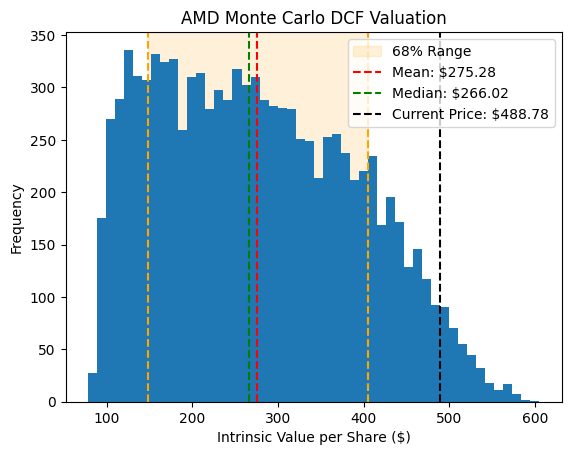

In [20]:
rgl = np.array(revenue_growth_list) #Revenue Growth list modified into an array
evml = np.array(ebitda_multiple_list) #EV/EBITDA list modified into an array
mean_equity_values = np.mean(equity_values)
median_equity_values = np.median(equity_values)
current_price = amd.info.get("currentPrice")

print(f'Simulations: {simulations}')
print("-"*30)
print(f"""Revenue Simulated:
Mean Revenue Growth: {np.mean(rgl) * 100:.2f}%
Min Revenue Growth: {rgl.min() * 100:.2f}%
Max Revenue Growth: {rgl.max() * 100:.2f}%""")
print("-"*30)
print(f"""EV/EBITDA Multiples Simulated:
Mean EV/EBITDA Multiple: {np.mean(evml):.2f}
Min EV/EBITDA Multiple: {(evml).min():.2f}
Max EV/EBITDA Multiple: {(evml).max():.2f}""")
print("-"*30)
print(f"Wacc: {wacc * 100:.3f}%")
print(f"Mean Value: ${np.mean(equity_values):.2f}")
print(f"Median Value: ${np.median(equity_values):.2f}")
print(f"16th Percentile: ${np.percentile(equity_values,16):.2f}")
print(f"84th Percentile: ${np.percentile(equity_values,84):.2f}")

plt.axvline(np.percentile(equity_values,16), color = 'orange', linestyle = '--', linewidth = 1.5)
plt.axvline(np.percentile(equity_values,84), color = 'orange', linestyle = '--', linewidth = 1.5)
plt.axvspan(np.percentile(equity_values, 16), np.percentile(equity_values, 84),
            color='orange', alpha=0.15, label='68% Range')

plt.axvline(mean_equity_values, color = 'red', linestyle = '--', linewidth = 1.5, label = f'Mean: ${mean_equity_values:.2f}')
plt.axvline(median_equity_values, color = 'green', linestyle = '--', linewidth = 1.5, label = f'Median: ${median_equity_values:.2f}')
plt.axvline(current_price, color = 'black', linestyle = '--', linewidth = 1.5, label = f'Current Price: ${current_price:.2f}')
plt.hist(equity_values, bins = 50)
plt.xlabel('Intrinsic Value per Share ($)')
plt.ylabel('Frequency')
plt.title('AMD Monte Carlo DCF Valuation')
plt.legend()
plt.show()

# Sensitivity Table Model (STM) Section

## WACC Rows and Exit Multiple Columns calculations

In [21]:


def betas_calculation(array_levered_adjusted_betas): #Betas calculation
    minimum_levered_adjusted_beta = (peer_adjusted_relevered_beta.min() + amd_hamada_beta)/2#for minimum parameter in beta row
    maximum_levered_adjusted_beta = (peer_adjusted_relevered_beta.max() + amd_hamada_beta)/2 #Blended worse beta with amd(Which is median) to repesent bear case scenarios more accurately
    return(minimum_levered_adjusted_beta, maximum_levered_adjusted_beta)

minimum_levered_adjusted_beta, maximum_levered_adjusted_beta = betas_calculation(array_levered_adjusted_betas)

beta_row = np.linspace(minimum_levered_adjusted_beta,maximum_levered_adjusted_beta,5) #find evenly spaced values between parameters (Adjusted mean beta and adjusted AMD beta)



In [22]:


def wacc_sensitivity_calculations(beta_row):

    wacc_sensitivity_row_values = []

    for beta in beta_row:

        E = market_cap

        Re = risk_free_rate + (beta * (expected_market_return - risk_free_rate))

        #[DEBT and COST OF DEBT]

        D =  int(BS.loc['Current Debt', '2025-12-31'] + BS.loc['Long Term Debt', '2025-12-31']) #BS.loc['row data, 'column data']

        Rd = IS.loc['Interest Expense', '2025-12-31']/D

        #[Capital Structure]
        V = E + D


        #[WACC calculations]

        wacc_beta_adjusted = ((E/V) * Re) + ((D/V) * Rd * (1 - corporate_tax_rate))

        wacc_sensitivity_row_values.append(wacc_beta_adjusted)

        wacc_sensitivity_row = np.array(wacc_sensitivity_row_values)

        wacc_sensitivity_row_rounded = [f'{round(wacc * 100, 2)}%' for wacc in wacc_sensitivity_row]

    return(wacc_sensitivity_row, wacc_sensitivity_row_rounded)

wacc_sensitivity_row, wacc_sensitivity_row_rounded = wacc_sensitivity_calculations(beta_row)

print(f'Wacc row: {wacc_sensitivity_row_rounded}')




Wacc row: ['12.75%', '13.09%', '13.44%', '13.78%', '14.13%']


In [23]:
def multiples_calculations(evml): #EV/EBITDA Multiples calculation
    start_multiple = evml.min()
    stop_multiple = evml.max()
    multiples_column = np.linspace(start_multiple,stop_multiple,5) #find evenly spaced values between specified parameter
    return(start_multiple, stop_multiple, multiples_column)

start_multiple, stop_multiple, multiples_column = multiples_calculations(evml)


multiples_column = np.linspace(start_multiple,stop_multiple,5)#find evenly spaced values between specified parameter
multiples_column_rounded = [round(multiples, 2) for multiples in multiples_column]
print(f'Multiples Column: {multiples_column}')

Multiples Column: [21.29666046 24.6156641  27.93466775 31.2536714  34.57267505]


# STM DCF calculations

In [24]:


def run_dcf(beta_applied, multiple_applied):

    starting_base_revenue = IS.iloc[0, -1]

    fy = [date.year for date in IS.loc['Operating Revenue'].dropna().index]

    #YEARS FORMAT

    current_year = 2026

    for years in range(1, projected_years + 1):

        current_year += 1

        fy.append(f'{current_year}E')

        forecasted_years = current_year




    revenue = IS.loc['Operating Revenue'].dropna().tolist()

    cogs = IS.loc['Cost Of Revenue'].dropna().tolist()

    capex = CFS.loc['Capital Expenditure'].dropna().tolist()

    ppe_gross = BS.loc['Gross PPE'].dropna().tolist()

    depreciation_expense = CFS.loc['Depreciation'].dropna().tolist()

    amortization_expense = IS.loc['Amortization'].dropna().tolist()

    sga = IS.loc['Selling General And Administration'].dropna().tolist()

    rnd = IS.loc['Research And Development'].dropna().tolist()



    #[REVENUE]


    for year in range(1, projected_years + 1):

        if year <= 2: #elevated growth for two years
            decay_rate = 0

        else:
            decay_rate -= decay_rate_assumption


        revenue_projected = revenue[-1] * (1 + (yoy_revenue_growth_assumption + decay_rate))

        revenue.append(revenue_projected)

    #[COGS]

    cogs_percent_of_revenue_list = []



    for historical_yrs in range(len(cogs)):

        cogs_percent_of_revenue = cogs[historical_yrs] / revenue[historical_yrs]

        cogs_percent_of_revenue_list.append(round(cogs_percent_of_revenue, 2))



    average_cogs_percent = sum(cogs_percent_of_revenue_list) / len(cogs)

    for forecast_yr in range(projected_years):

        if forecast_yr < 3:

            cogs_future = average_cogs_percent * revenue[4 + forecast_yr]

            cogs.append(cogs_future)

            average_cogs_percent -= 0.01

        elif forecast_yr >= 3:

            cogs_future = average_cogs_percent * revenue[4 + forecast_yr]

            cogs.append(cogs_future)



                                        ### GROSS PROFIT ###

    gp = [] #VALUE

    for y in range(total_years):

        profit = revenue[y] - cogs[y]

        gp.append(profit)


                                        ### DEPRECIATION SCHEDULE ###

    #[CAPEX]

    capex_percent_of_revenue_list = []



    for historical_yr in range(len(capex)):

        capex_percent_of_revenue = capex[historical_yr] / revenue[historical_yr]

        capex_percent_of_revenue_list.append(capex_percent_of_revenue)

        average_capex_percent = sum(capex_percent_of_revenue_list) / len(capex)



    for forecast_yrs in range(projected_years):

        capex_future = average_capex_percent * revenue[4 + forecast_yrs]

        capex.append(capex_future)


    #[GROSS PPE]#

    for years in range(projected_years):

        # Using 3 + years matching your original logic tracking index offset

        ppe_gross.append(ppe_gross[3 + years] + abs(capex[4 + years]))



    #[DEPRECIATION]

    historical_depreciation_rate = []



    for historical_yr in range(len(depreciation_expense)):

        rate = depreciation_expense[historical_yr] / ppe_gross[historical_yr]

        historical_depreciation_rate.append(rate)

        avg_rate = sum(historical_depreciation_rate) / len(historical_depreciation_rate)

    for forecast_yr in range(projected_years):

        beginning_ppe = ppe_gross[4 - 1 + forecast_yr]

        depreciation_t = beginning_ppe * avg_rate

        depreciation_expense.append(depreciation_t)



                                        ### AMORTIZATION CALCULATIONS ###

    #Amortization​= [Amortization current year − 1] × (1+g)

        # Amortization CAGR

    n = len(amortization_expense) - 1

    g_cagr = (amortization_expense[-1] / amortization_expense[0]) ** (1/n) - 1



        # average YoY amortization growth

    yoy_amortization_growth = []



    for y in range(1, len(amortization_expense)):

        yoy_amortization_growth.append(amortization_expense[y] / amortization_expense[y-1] - 1)



    g_avg = sum(yoy_amortization_growth) / len(yoy_amortization_growth)



    # blended rate

    g = 0.5 * g_cagr + 0.5 * g_avg

    ### [amortization calculations] ###

    for years in range(projected_years):

        projected_amortization = amortization_expense[-1] * (1 + g)

        amortization_expense.append(round(projected_amortization,1))



                                            ### OPERATING EXPENSES ###

    #[SGA]

    sga_percent_of_revenue_list = []



    for historical_yrs in range(len(sga)):

       sga_percent_of_revenue = sga[historical_yrs]/revenue[historical_yrs]

       sga_percent_of_revenue_list.append(sga_percent_of_revenue)

    sga_margin = sum(sga_percent_of_revenue_list)/len(sga)



    for forecast_yrs in range(projected_years):

        if forecast_yrs < 1:

            sga_future = sga_margin * revenue[4 + forecast_yrs]

            sga.append(sga_future)

        elif 1 <= forecast_yrs < 4:

            sga_margin -= 0.007

            sga_future =  sga_margin * revenue[4 + forecast_yrs]

            sga.append(sga_future)

        elif forecast_yrs == 4:

           sga_future =  sga_margin * revenue[4 + forecast_yrs]

           sga.append(sga_future)



    #[RND]

    rnd_percent_of_revenue_list = []

    y = 0

    for historical_yrs in range(len(rnd)):

       rnd_percent_of_revenue = rnd[historical_yrs]/revenue[historical_yrs]

       rnd_percent_of_revenue_list.append(rnd_percent_of_revenue)

       rnd_margin = sum(rnd_percent_of_revenue_list)/len(rnd)



    for forecast_yrs in range(projected_years):

        if forecast_yrs < 1:

            rnd_future = rnd_margin * revenue[4 + forecast_yrs]

            rnd.append(rnd_future)

        elif 1 <= forecast_yrs < 4:

            rnd_margin -= 0.02

            rnd_future =  rnd_margin * revenue[4 + forecast_yrs]

            rnd.append(rnd_future)

        elif forecast_yrs == 4:

           rnd_future =  rnd_margin * revenue[4 + forecast_yrs]

           rnd.append(rnd_future)



    #[D&A]

    depreciation_and_amortization = IS.loc['Depreciation And Amortization In Income Statement'].dropna().tolist()

    for y in range(projected_years):

        combined = depreciation_expense[4 + y] + abs(amortization_expense[4 + y])

        depreciation_and_amortization.append(combined)




    #[OTHER OPERATING EXPENSES]

    ooe = IS.loc['Other Operating Expenses'].tolist()

    ooe_percent_of_revenue_list = [] #VALUE



    for historical_yrs in range(len(ooe)):

        ooe_percent_of_revenue = ooe[historical_yrs]/revenue[historical_yrs]

        ooe_percent_of_revenue_list.append(ooe_percent_of_revenue)

    average_ooe_percent = sum(ooe_percent_of_revenue_list)/len(ooe)



    for forecast_yrs in range(projected_years):

        ooe_future = average_ooe_percent * revenue[4 + forecast_yrs]

        ooe.append(ooe_future)



    #[TOTAL OPERATING EXPENSE]

    opex = []

    for y in range(total_years):

        annual_operating_expense = (

            sga[0 + y]

            + rnd[0 + y]

            + depreciation_and_amortization[0 + y]

        )

        opex.append(annual_operating_expense)



                                        ### OPERATING PROFIT ###

    historical_and_projected_ebit = IS.loc['Operating Income'].tolist()

    for y in range(projected_years):

        ebit = (

            gp[4 + y]

            - sga[4 + y]

            - rnd[4 + y]

            - depreciation_and_amortization[4 + y]

        )

        historical_and_projected_ebit.append(ebit)



                                        ### NOPAT CALCULATIONS ###

    nopat = [ebit * (1-corporate_tax_rate) for ebit in historical_and_projected_ebit]




                                ### CHANGE IN NET WORKING CAPITAL CALCULATIONS  ###

    #[ACCOUNTS RECEIVABLE]

    accounts_receivable = BS.loc['Accounts Receivable'].tolist()

    dso = [(accounts_receivable[years] * 365) / revenue[years] for years in range(historical_years)]

    avg_dso = sum(dso) / len(dso)



    for years in range(projected_years):

        projected_accounts_receivable = avg_dso * revenue[4 + years] / 365

        accounts_receivable.append(projected_accounts_receivable)



    #[INVENTORY]

    inventory = BS.loc['Inventory'].tolist()

    dio = [(inventory[years] * 365) / cogs[years] for years in range(historical_years)]

    avg_dio = sum(dio) / len(dio)



    for years in range(projected_years):

        projected_inventory = avg_dio * cogs[4 + years] / 365

        inventory.append(projected_inventory)



    #[ACCOUNTS PAYABLE]

    accounts_payable = BS.loc['Accounts Payable'].tolist()

    dpo = [(accounts_payable[years] * 365) / cogs[years] for years in range(historical_years)]

    avg_dpo = sum(dpo) / len(dpo)



    for years in range(projected_years):

        projected_accounts_payable = avg_dpo * cogs[4 + years] / 365

        accounts_payable.append(projected_accounts_payable)



    #[ACCURED EXPENSES]


    accured_expenses = BS.loc['Current Accrued Expenses'].tolist()

    ae_percent_of_opex = [accured_expenses[years] / opex[years] for years in range(historical_years)]

    opex_margin = sum(ae_percent_of_opex) / len(ae_percent_of_opex)



    for years in range(projected_years):

        projected_ae = opex_margin * opex[years]

        accured_expenses.append(projected_ae)



    #[OTHER ASSETS]

    other_current_assets = BS.loc['Other Current Assets'].tolist()

    oca_percent_of_revenue = [other_current_assets[years] / revenue[years] for years in range(historical_years)]

    oca_margin = sum(oca_percent_of_revenue) / len(oca_percent_of_revenue)



    for years in range(projected_years):

        projected_oca = oca_margin * revenue[years]

        other_current_assets.append(projected_oca)


    #[NET WORKING CAPITAL]

    net_wc = []

    for y in range(total_years):

        annual_net_wc = (

            accounts_receivable[y]

            + inventory[y]

            + other_current_assets[y]

            - accounts_payable[y]

            - accured_expenses[y]

        )

        net_wc.append(annual_net_wc)


    ### [CHANGE IN NWC CALCULATIONS] ###

    change_in_net_wc = [] #VALUE

    for years in range(total_years):

        if years == 0:

            change_in_net_wc.append(0)

        elif years >= 1:

            change = net_wc[years] - net_wc[years - 1]

            change_in_net_wc.append(change)



                                        ### FREE CASH FLOW ###

    fcf = [nopat[years] + depreciation_expense[years] - capex[years] - change_in_net_wc[years]

    for years in range(total_years)]



                                        ### WACC ###


    #[EQUITY and COST OF EQUITY]

    E = market_cap

    Re = risk_free_rate + (beta_applied * (expected_market_return - risk_free_rate))

    #[DEBT and COST OF DEBT]

    D =  int(BS.loc['Current Debt', '2025-12-31'] + BS.loc['Long Term Debt', '2025-12-31']) #BS.loc['row data, 'column data']

    Rd = IS.loc['Interest Expense', '2025-12-31']/D

    #[Capital Structure]
    V = E + D


    #[WACC calculations]

    wacc = ((E/V) * Re) + ((D/V) * Rd * (1 - corporate_tax_rate))


                                        ### PRESENT VALUE OF FCF ###

    projected_fcf_discounted_base = np.array(fcf[-projected_years:])

    years = np.arange(1,projected_years + 1)


    pv_fcf = projected_fcf_discounted_base / ((1 + wacc) ** years) #PRESENT VALUE




                                        ### TERMINAL VALUE ###

    pv_terminal = (historical_and_projected_ebit[8] + depreciation_and_amortization[8])/(1 + wacc)**projected_years * multiple_applied


                                        ### ENTERPRISE VALUE ###

    enterprise_value = sum(pv_fcf) + pv_terminal


                                        ### EQUITY VALUE ###

    total_debt = D

    equity_value = enterprise_value - total_debt



                                        ### PPS ###

    intrinstic_value = equity_value/shares_outstanding * ((1 + share_dilution_rate) ** projected_years)




    return(intrinstic_value)






In [25]:
def sensitivity_table_final(wacc_sensitivity_row, multiples_column):
    sensitivity_results = np.zeros((5,5))

    for w, wacc in enumerate(wacc_sensitivity_row):
        for m, multiple in enumerate(multiples_column):
            price = run_dcf(beta_applied = wacc, multiple_applied = multiple)
            sensitivity_results[w,m] = round(price,2)

    return(sensitivity_results)

sensitivity_results = sensitivity_table_final(wacc_sensitivity_row, multiples_column)



# STM Results Displayed

In [26]:
sensitivity_table = pd.DataFrame(sensitivity_results, index = wacc_sensitivity_row_rounded, columns = multiples_column_rounded)
sensitivity_table

,21.30,24.62,27.93,31.25,34.57
12.75%,402.63,461.10,519.58,578.06,636.53
13.09%,402.30,460.72,519.15,577.58,636.01
13.44%,401.97,460.35,518.72,577.10,635.48
13.78%,401.64,459.97,518.30,576.63,634.96
14.13%,401.31,459.59,517.87,576.15,634.44
